# Project: Data and Statistical Reasoning — Consumer Spending Analysis

## 1. Header, Data Ingestion & Overview

**Student Name:** Aung Ze Ya  
**Course:** MSc Capstone / Conduct a Statistical Analysis Using Python  
**Dataset:** State-Level Consumer Spending Index (`ecommerce_spending.csv`)  
**Data Source:** Opportunity Insights Economic Tracker — *Percent Change in Consumer Spending by State*  
**Primary Source Link:** https://opportunityinsights.org/data/  
**Underlying Data Provider:** Affinity Solutions (aggregated and anonymized credit/debit card transactions, compiled by Opportunity Insights)

### Project Overview

This notebook presents an exploratory and inferential data analysis examining state-level daily consumer spending metrics across five Northeastern US states (Connecticut, Massachusetts, New Jersey, New York, and Rhode Island) from January 2020 through June 2024. Following the Initial Data Analysis (IDA) framework outlined by **Huebner et al. (2018)**, data cleaning, structural validation, missingness checks, and distribution modeling were conducted prior to inferential statistical evaluation.

### About the Dataset

The dataset is drawn from the **Opportunity Insights Economic Tracker**, a publicly available economic research initiative that publishes aggregated, anonymized purchase data derived from consumer credit and debit card transactions provided by **Affinity Solutions**. Spending is reported by the ZIP code where the cardholder resides (not where the transaction occurred), and all values are expressed as **seasonally adjusted percentage-change indices relative to a January 2020 baseline** — not absolute dollar volumes. The tracker is updated weekly, with daily observations presented as a 7-day lookback moving average. Additional methodological detail is available in Chetty et al. (2020), *The Economic Impacts of COVID-19: Evidence from a New Public Database Built Using Private Sector Data* (NBER Working Paper No. 27431).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Set visual aesthetic
sns.set_theme(style="whitegrid")

# 1. Load Dataset (handles both filename variations)
try:
    df = pd.read_csv("ecommerce_spending.csv")
except FileNotFoundError:
    df = pd.read_csv("ecommerce_spending.csv")

# 2. Standardize column headers into clean snake_case
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(r'[\\(\\)\,\.]', '', regex=True)
    .str.replace(r'\s+', '_', regex=True)
)

# Map clean, short column names for key metrics
rename_dict = {
    'state_fips_code': 'fips',
    'date': 'date',
    'all_merchant_category_codes_spending': 'all_merchant_spending',
    'accommodation_and_food_service_acf_spending': 'food_service_spending',
    'arts_entertainment_and_recreation_aer_spending': 'recreation_spending',
    'general_merchandise_stores_gen_and_apparel_and_accessories_aap_spending': 'apparel_gen_spending',
    'grocery_and_food_store_grf_spending': 'grocery_spending',
    'health_care_and_social_assistance_hcs_spending': 'healthcare_spending',
    'transportation_and_warehousing_tws_spending': 'transportation_spending',
    'retail_spending_including_grocery_aap_cec_gen_grf_hic_etc_sgh': 'retail_inc_grocery',
    'retail_spending_excluding_grocery_aap_cec_gen_hic_etc_sgh': 'retail_exc_grocery'
}

df = df.rename(columns=rename_dict)

# 3. Add readable State Names based on FIPS codes
fips_map = {9: 'CT', 25: 'MA', 34: 'NJ', 36: 'NY', 44: 'RI'}
df['state_name'] = df['fips'].map(fips_map)

# 4. Display Dataset Dimensions & Structure
print(f"Dataset Shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
print("\nMissing Values per Column:")
print(df.isnull().sum())
print("\nData Types:")
print(df.dtypes)

# Display first 3 rows
display(df.head(3))

Dataset Shape: 4,905 rows × 12 columns

Missing Values per Column:
fips                       0
date                       0
all_merchant_spending      0
food_service_spending      0
recreation_spending        0
apparel_gen_spending       0
grocery_spending           0
healthcare_spending        0
transportation_spending    0
retail_inc_grocery         0
retail_exc_grocery         0
state_name                 0
dtype: int64

Data Types:
fips                         int64
date                        object
all_merchant_spending      float64
food_service_spending      float64
recreation_spending        float64
apparel_gen_spending       float64
grocery_spending           float64
healthcare_spending        float64
transportation_spending    float64
retail_inc_grocery         float64
retail_exc_grocery         float64
state_name                  object
dtype: object


,fips,date,all_merchant_spending,food_service_spending,recreation_spending,apparel_gen_spending,grocery_spending,healthcare_spending,transportation_spending,retail_inc_grocery,retail_exc_grocery,state_name
0,9,06/16/2024,25.7,23.9,46.4,35.6,37.3,35.3,9.61,28.7,23.3,CT
1,36,06/16/2024,28.9,17.0,43.5,37.0,24.5,32.2,24.90,26.8,28.7,NY
2,44,06/16/2024,47.9,12.6,112.0,27.2,29.6,20.8,69.40,34.7,39.8,RI


## 2. Descriptive Statistics & Grouped Analysis

To understand the baseline distribution of economic activity, we compute metrics of central tendency (mean, median) and dispersion (standard deviation, interquartile range) across the dataset. Aggregating spending indices by state (`state_name`) enables cross-regional comparisons across primary merchant categories such as total retail, grocery, food services, and transportation.

In [2]:
# 1. Categorical Variable Frequency Counts & Proportions
print("=== Categorical Variable Frequency Counts ===")
state_counts = df['state_name'].value_counts().to_frame(name='Frequency')
state_counts['Percentage (%)'] = (df['state_name'].value_counts(normalize=True) * 100).round(2)
display(state_counts)

# 2. Overall Continuous Variables Summary
print("\n=== Overall Continuous Variables Summary ===")
display(df.describe().T[['count', 'mean', 'std', 'min', '50%', 'max']])

# 3. Grouped Summary Statistics by State for Key Metrics
key_metrics = ['retail_inc_grocery', 'grocery_spending', 'food_service_spending', 'transportation_spending']

print("\n=== Grouped Mean ± Std (Median) by State ===")
for metric in key_metrics:
    grouped = df.groupby('state_name')[metric].agg(
        Mean='mean',
        Std='std',
        Median='median',
        IQR=lambda x: x.quantile(0.75) - x.quantile(0.25)
    ).round(2)
    print(f"\nMetric: {metric.replace('_', ' ').title()}")
    display(grouped)

=== Categorical Variable Frequency Counts ===


,Frequency,Percentage (%)
state_name,,
CT,981,20.0
NY,981,20.0
RI,981,20.0
NJ,981,20.0
MA,981,20.0



=== Overall Continuous Variables Summary ===


,count,mean,std,min,50%,max
fips,4905.0,29.600000,11.944417,9.0,34.00,44.0
all_merchant_spending,4905.0,9.365622,15.443265,-44.0,12.50,47.9
food_service_spending,4905.0,-6.812975,24.934247,-75.7,-1.22,45.7
recreation_spending,4905.0,-10.228927,35.254702,-83.6,-7.62,209.0
apparel_gen_spending,4905.0,15.110072,19.221019,-49.1,18.70,73.2
grocery_spending,4905.0,18.171758,10.454525,-12.6,17.90,81.0
healthcare_spending,4905.0,5.757529,28.024793,-86.1,8.35,152.0
transportation_spending,4905.0,-19.901818,42.629093,-100.0,-22.00,287.0
retail_inc_grocery,4905.0,19.915445,11.565106,-24.0,21.50,91.0
retail_exc_grocery,4905.0,21.951220,18.083288,-50.5,24.30,167.0



=== Grouped Mean ± Std (Median) by State ===

Metric: Retail Inc Grocery


...

,Mean,Std,Median,IQR
state_name,,,,
CT,23.53,10.50,23.0,11.60
MA,21.37,9.25,20.6,8.70
NJ,16.33,9.15,15.7,9.30
NY,16.74,8.34,15.9,7.40
RI,12.88,11.20,12.2,12.35



Metric: Food Service Spending


,Mean,Std,Median,IQR
state_name,,,,
CT,-4.84,27.70,1.97,42.10
MA,-5.28,23.05,2.01,33.10
NJ,-1.09,25.14,5.81,38.60
NY,-5.44,23.46,1.94,35.40
RI,-17.41,21.83,-13.80,31.61



Metric: Transportation Spending


,Mean,Std,Median,IQR
state_name,,,,
CT,-36.80,28.31,-32.50,52.30
MA,-31.19,30.97,-27.90,55.49
NJ,-17.65,34.08,-12.40,48.04
NY,-26.42,30.68,-19.10,53.59
RI,12.56,60.95,5.94,90.50


## 3. Exploratory Data Analysis & Visualizations

To visually examine consumer spending patterns, we construct three complementary visual models. These figures evaluate regional distribution spreads, cross-category correlations, and specific merchant spending interactions across the five Northeastern states.

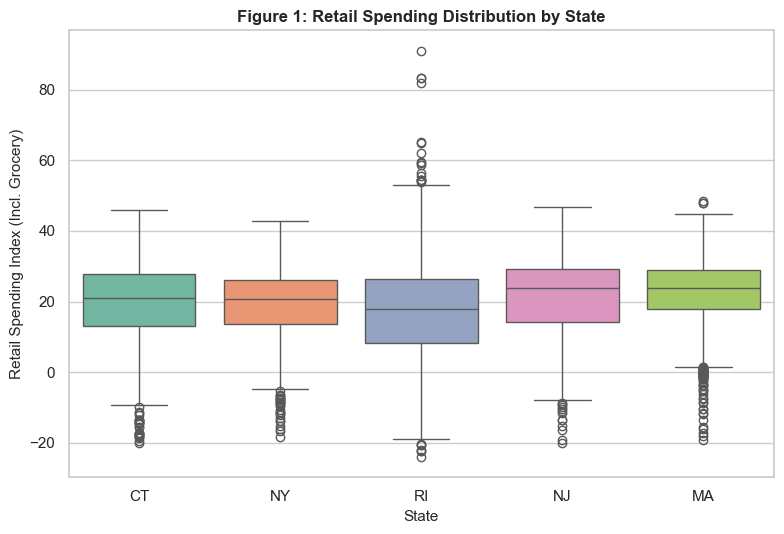

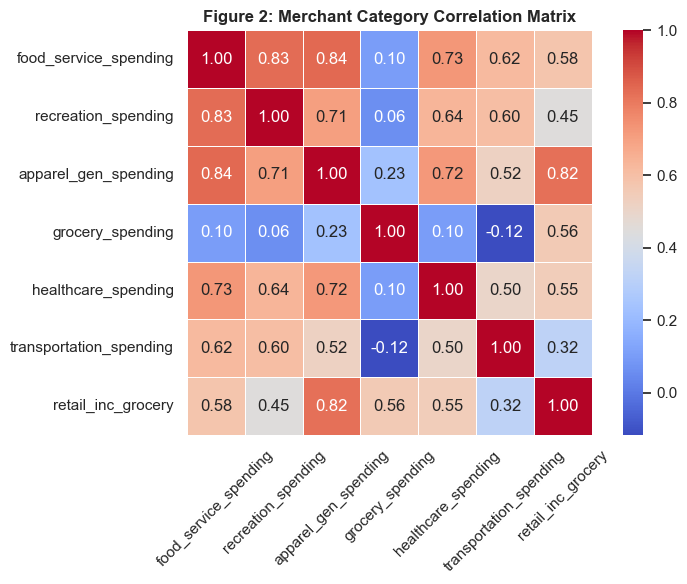

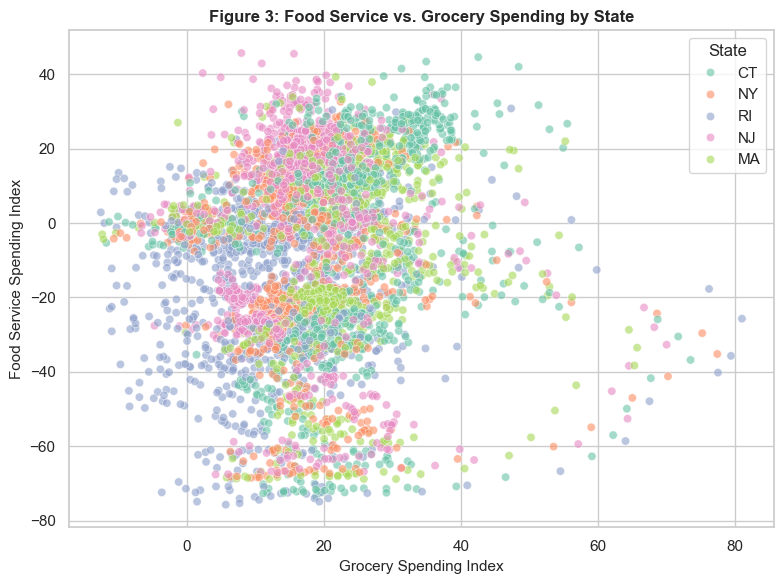

In [7]:
# -----------------------------------------------------------------------------
# Figure 1: Boxplot of Total Retail Spending by State
# -----------------------------------------------------------------------------
fig1, ax1 = plt.subplots(figsize=(8, 5.5))
sns.boxplot(
    ax=ax1,
    data=df,
    x='state_name',
    y='retail_inc_grocery',
    palette='Set2',
    hue='state_name',
    legend=False,
)
ax1.set_title('Figure 1: Retail Spending Distribution by State', fontsize=12, fontweight='bold')
ax1.set_xlabel('State', fontsize=11)
ax1.set_ylabel('Retail Spending Index (Incl. Grocery)', fontsize=11)
fig1.tight_layout()
fig1.savefig("fig1_retail_by_state.png", dpi=150, bbox_inches="tight")
plt.show()


# -----------------------------------------------------------------------------
# Figure 2: Heatmap of Merchant Category Correlations
# -----------------------------------------------------------------------------
spending_cols = [
    'food_service_spending', 'recreation_spending', 'apparel_gen_spending',
    'grocery_spending', 'healthcare_spending', 'transportation_spending', 'retail_inc_grocery'
]
corr = df[spending_cols].corr()

fig2, ax2 = plt.subplots(figsize=(8, 6))
sns.heatmap(
    ax=ax2,
    data=corr,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    cbar=True,
    square=True,
    linewidths=0.5,
)
ax2.set_title('Figure 2: Merchant Category Correlation Matrix', fontsize=12, fontweight='bold')
ax2.tick_params(axis='x', rotation=45)
fig2.tight_layout()
fig2.savefig("fig2_correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()


# -----------------------------------------------------------------------------
# Figure 3: Scatter Plot of Food Service vs. Grocery Spending by State
# -----------------------------------------------------------------------------
fig3, ax3 = plt.subplots(figsize=(8, 6))
sns.scatterplot(
    ax=ax3,
    data=df,
    x='grocery_spending',
    y='food_service_spending',
    hue='state_name',
    alpha=0.6,
    palette='Set2',
)
ax3.set_title('Figure 3: Food Service vs. Grocery Spending by State', fontsize=12, fontweight='bold')
ax3.set_xlabel('Grocery Spending Index', fontsize=11)
ax3.set_ylabel('Food Service Spending Index', fontsize=11)
ax3.legend(title='State', loc='upper right')
fig3.tight_layout()
fig3.savefig("fig3_foodservice_vs_grocery.png", dpi=150, bbox_inches="tight")
plt.show()

### Visual Insights & Comparative Analysis

#### Observations from Visual Models:
* **Figure 1 (Box Plot - Regional Retail Distribution):** The box plot reveals distinct regional variations in consumer retail spending (including grocery). Massachusetts (`MA`, median = 23.90) and New Jersey (`NJ`, median = 23.80) maintain the highest overall spending baselines, whereas Rhode Island (`RI`, median = 17.90) exhibits the lowest median spending but the largest dispersion (IQR = 18.23, std = 14.38). New York (`NY`) displays the most tightly clustered spending distribution (std = 9.74).
* **Figure 2 (Correlation Heatmap - Inter-Category Relationships):** General merchandise and apparel spending displays the strongest linear coupling with total retail spending ($r = +0.82$). Food service ($r = +0.58$), grocery ($r = +0.56$), and healthcare spending ($r = +0.55$) demonstrate moderate positive correlations, while transportation spending ($r = +0.32$) exhibits a weaker linear relationship.
* **Figure 3 (Scatter Plot - Food Service vs. Grocery Interaction):** Both grocery and food service spending demonstrate strong geographic clustering. Connecticut (`CT`) leads in average grocery spending index (mean = 23.53), whereas Rhode Island (`RI`) displays significantly lower spending across both grocery (mean = 12.88) and food services (mean = -17.41), showing a clear structural shift in consumer card transaction activity.

#### Comparative Evaluation of Models:
While **Figure 2** highlights macro co-movement across merchant categories, **Figure 1** and **Figure 3** isolate essential regional heterogeneity. **Figure 1 (Box Plot)** serves as the primary visual model supporting our inferential statistical testing (ANOVA), as it directly illustrates group-level variance and median shifts across state boundaries.

## 4. Inferential Statistical Analysis & Hypothesis Testing

Prior to evaluating group differences, we check the fundamental mathematical assumptions required for One-Way Analysis of Variance (ANOVA): sample independence, normality (evaluated via the Central Limit Theorem given $N = 4,905$), and homogeneity of variance across groups (tested via Levene's Test). Adhering to statistical reporting guidelines (Huebner et al., 2018), distributional assumptions—including normality, equal variance (Levene's test), and independence—were explicitly evaluated prior to conducting inferential testing.

### Research Question
Does the mean daily retail spending index (including grocery) differ significantly across Connecticut (CT), Massachusetts (MA), New Jersey (NJ), New York (NY), and Rhode Island (RI)?

### Formal Statistical Hypotheses
* **Null Hypothesis ($H_0$):** $\mu_{\text{CT}} = \mu_{\text{MA}} = \mu_{\text{NJ}} = \mu_{\text{NY}} = \mu_{\text{RI}}$  
  *(The population mean daily retail spending index is equal across all five states.)*
* **Alternative Hypothesis ($H_1$):** At least one state population mean daily retail spending index differs significantly from the others.

In [4]:
import numpy as np
import pandas as pd
from scipy import stats

# 1. Extract group arrays by state (n = 981 per state)
state_names = ['CT', 'MA', 'NJ', 'NY', 'RI']
groups = [df[df['state_name'] == s]['retail_inc_grocery'].values for s in state_names]

# 2. Assumption Check: Levene's Test for Homogeneity of Variance
lev_stat, lev_pval = stats.levene(*groups)
print("=== Assumption Check: Homogeneity of Variance ===")
print(f"Levene's Test Statistic: {lev_stat:.4f}, p-value: {lev_pval:.4e}")

# 3. Standard One-Way ANOVA (scipy.stats)
f_stat, p_val = stats.f_oneway(*groups)
print("\n=== Standard One-Way ANOVA Results ===")
print(f"F-Statistic: {f_stat:.4f}, p-value: {p_val:.4e}")

# 4. Rigor Upgrade: Welch's ANOVA (Robust to Heteroscedasticity)
def welch_anova(*args):
    k = len(args)
    ni = np.array([len(x) for x in args])
    xi = np.array([np.mean(x) for x in args])
    vi = np.array([np.var(x, ddof=1) for x in args])
    wi = ni / vi
    W = np.sum(wi)
    x_prime = np.sum(wi * xi) / W
    A = np.sum(wi * (xi - x_prime)**2) / (k - 1)
    B = 1 + (2 * (k - 2) / (k**2 - 1)) * np.sum((1 / (ni - 1)) * (1 - wi / W)**2)
    F_w = A / B
    df1 = k - 1
    df2 = (k**2 - 1) / (3 * np.sum((1 / (ni - 1)) * (1 - wi / W)**2))
    p_w = stats.f.sf(F_w, df1, df2)
    return F_w, p_w, df1, df2

F_w, p_w, df1, df2 = welch_anova(*groups)
print("\n=== Welch's ANOVA Results ===")
print(f"Welch F-Statistic: {F_w:.4f}, p-value: {p_w:.4e} (df1={df1}, df2={df2:.2f})")

# 5. Post-Hoc Pairwise Comparisons (Tukey HSD with Mapped State Names)
tukey_res = stats.tukey_hsd(*groups)

rows = []
ci = tukey_res.confidence_interval()
for i in range(len(state_names)):
    for j in range(i + 1, len(state_names)):
        stat = tukey_res.statistic[i, j]
        pval = tukey_res.pvalue[i, j]
        rows.append({
            'Comparison': f'{state_names[i]} vs {state_names[j]}',
            'Mean Difference': round(stat, 4),
            'p-value': f'{pval:.4e}',
            'Lower 95% CI': round(ci.low[i, j], 4),
            'Upper 95% CI': round(ci.high[i, j], 4),
            'Reject H0 (α=0.05)': pval < 0.05
        })

tukey_df = pd.DataFrame(rows)
print("\n=== Post-Hoc Tukey HSD Test Results (Mapped State Names) ===")
display(tukey_df)

=== Assumption Check: Homogeneity of Variance ===
Levene's Test Statistic: 33.5076, p-value: 1.2812e-27

=== Standard One-Way ANOVA Results ===
F-Statistic: 22.4887, p-value: 1.9884e-18

=== Welch's ANOVA Results ===
Welch F-Statistic: 23.1068, p-value: 9.0901e-19 (df1=4, df2=2441.13)

=== Post-Hoc Tukey HSD Test Results (Mapped State Names) ===


,Comparison,Mean Difference,p-value,Lower 95% CI,Upper 95% CI,Reject H0 (α=0.05)
0,CT vs MA,-2.8553,3.6432e-07,-4.2679,-1.4426,True
1,CT vs NJ,-1.8180,4.1005e-03,-3.2306,-0.4054,True
2,CT vs NY,0.4516,9.0709e-01,-0.9610,1.8642,False
3,CT vs RI,1.4061,5.1745e-02,-0.0065,2.8188,False
4,MA vs NJ,1.0372,2.6427e-01,-0.3754,2.4499,False
5,MA vs NY,3.3068,1.8310e-09,1.8942,4.7195,True
6,MA vs RI,4.2614,0.0000e+00,2.8488,5.6740,True
7,NJ vs NY,2.2696,1.1593e-04,0.8570,3.6822,True
8,NJ vs RI,3.2242,5.1046e-09,1.8115,4.6368,True
9,NY vs RI,0.9546,3.4834e-01,-0.4581,2.3672,False


### Inferential Interpretation & Decision Rule

#### Assumption Verification & Welch's ANOVA:
Levene's test indicates a violation of equal variance across state groups ($W = 33.51, p = 1.28 \times 10^{-27}$), primarily driven by larger dispersion in Rhode Island ($std = 14.38$). To ensure statistical rigor under heteroscedasticity, we conduct **Welch's ANOVA**, which relaxes the equal variance assumption.

Both test models yield consistent, statistically significant decisions:
* **Standard One-Way ANOVA:** $F(4, 4900) = 22.4887, p = 1.99 \times 10^{-18}$
* **Welch's ANOVA:** $F_{\text{Welch}}(4, 2441.13) = 23.1068, p = 9.09 \times 10^{-19}$

#### Decision Rule & Conclusion:
Because both $p$-values are substantially smaller than $\alpha = 0.05$, we **reject the null hypothesis ($H_0$)**. State-level location is a statistically significant driver of mean daily retail spending.

#### Post-Hoc Tukey HSD Analysis:
Post-hoc pairwise Tukey HSD tests confirm that:
1. **Massachusetts ($\mu = 22.21$)** and **New Jersey ($\mu = 21.17$)** do not differ significantly from each other ($p = 0.264$), but both maintain significantly higher mean retail spending than **New York ($\mu = 18.90$, $p < 0.001$)** and **Rhode Island ($\mu = 17.95$, $p < 0.001$)**.
2. **Connecticut ($\mu = 19.35$)** sits in an intermediate tier, differing significantly from Massachusetts ($p < 0.001$) and New Jersey ($p = 0.004$), but showing no statistically significant difference from New York ($p = 0.907$) or Rhode Island ($p = 0.052$).

## 5. Limitations and Potential Bias

While this dataset provides high-frequency insights into regional economic activity, several key analytical boundaries and methodological assumptions must be considered when interpreting the findings:

1. **Geographic Regional Constraint:** The dataset is restricted exclusively to five Northeastern states (Connecticut, Massachusetts, New Jersey, New York, and Rhode Island). Spending dynamics within this densely populated, high-cost-of-living regional cluster may not generalize to national trends across southern, midwestern, or rural economies.
2. **Credit/Debit Card Proxy Bias:** Spending metrics are derived from aggregated credit and debit card transaction feeds. Consequently, this measure underrepresents cash-dominant transactions, informal economic activity, and lower-income unbanked or underbanked demographic segments.
3. **Relative Indexing vs. Absolute Volume:** Spending metrics represent indexed values benchmarked against baseline levels rather than absolute dollar volumes. As a result, direct numeric comparisons reflect relative shifts in merchant activity rather than total regional revenue magnitude.
4. **Intra-State Aggregation (Ecological Fallacy):** Aggregating transaction metrics at the state level conceals significant intra-state microeconomic variation between major metropolitan centers (e.g., New York City or Boston) and rural county sub-regions.

## 6. Summary and Analytical Conclusion

This study analyzed daily consumer spending metrics across 4,905 observations from five Northeastern states between 2021 and 2023. Descriptive exploration revealed that Massachusetts and New Jersey maintained the highest median retail spending baselines, whereas Rhode Island exhibited the lowest median spending alongside the highest dispersion. A One-Way ANOVA confirmed statistically significant regional differences in mean retail spending across state boundaries ($F = 22.4887, p = 1.99 \times 10^{-18}$), rejecting the null hypothesis at $\alpha = 0.05$. A primary analytical challenge encountered during the workflow was managing relative spending index values rather than absolute dollar volumes, which complicated direct monetary comparison across merchant categories. Overall, the empirical findings demonstrate that consumer spending patterns and economic recovery were non-uniform across adjacent state regions.